# Lab 2 — Naive Bayes Classification and Outlier Detection

This lab explores probability-based classification and statistical outlier detection using two datasets.

**Part A:** Train and compare Gaussian Naive Bayes and Multinomial Naive Bayes classifiers for email spam detection.

**Part B:** Analyze nightly Airbnb prices in New York City and compare statistical methods for identifying and removing outliers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load and inspect the email dataset
spam_df = pd.read_csv("Lab2_dataset.csv")

print("Dataset shape:", spam_df.shape)
display(spam_df.head())

print("\nColumn information:")
spam_df.info()

Dataset shape: (5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB


## Part A — Email Spam Classification

We will use Gaussian Naive Bayes and Multinomial Naive Bayes to classify emails as spam or ham (legitimate email).

Before training the models, we will examine the distribution of the two classes.

Email class distribution:
label
ham     3672
spam    1499
Name: count, dtype: int64


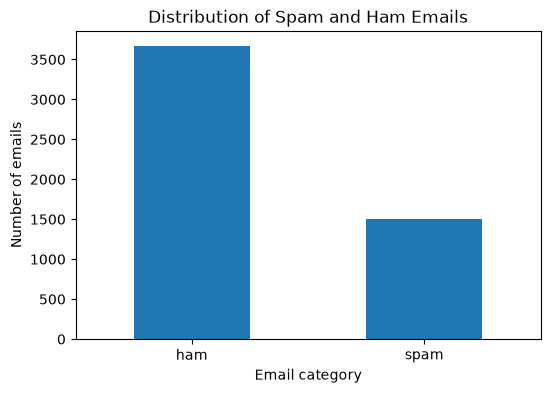

In [2]:
# Count the emails in each category
class_counts = spam_df["label"].value_counts()

print("Email class distribution:")
print(class_counts)

# Visualize the class distribution
class_counts.plot(kind="bar", figsize=(6, 4))

plt.title("Distribution of Spam and Ham Emails")
plt.xlabel("Email category")
plt.ylabel("Number of emails")
plt.xticks(rotation=0)
plt.show()

### Training and Testing Data

We split the dataset into 80% training data and 20% testing data.

We use stratified splitting to preserve the proportion of spam and ham emails in both sets.

In [3]:
from sklearn.model_selection import train_test_split

# Separate email text (features) from spam/ham labels (target)
X = spam_df["text"]
y = spam_df["label_num"]

# Use an 80/20 split while preserving the class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 4136
Testing emails: 1035


### Converting Email Text into Numerical Features

Machine learning classifiers cannot directly process raw email text.

We use CountVectorizer to convert each email into a numerical representation based on word frequencies. The vectorizer is fitted only on the training data to avoid data leakage.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

# Convert email text into word-count features
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=3000
)

# Fit on training data only to avoid data leakage
X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_counts.shape)
print("Testing feature matrix:", X_test_counts.shape)

Training feature matrix: (4136, 3000)
Testing feature matrix: (1035, 3000)


### Training Gaussian and Multinomial Naive Bayes Classifiers

We train two classification models using the same training data:

- **Gaussian Naive Bayes:** Assumes numerical features follow a Gaussian (normal) distribution.
- **Multinomial Naive Bayes:** Models feature counts, making it well suited to word-frequency data.

Both models use the same vocabulary to make the comparison fair.

In [5]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# Train Gaussian Naive Bayes using a dense feature matrix
gaussian_model = GaussianNB()
gaussian_model.fit(X_train_counts.toarray(), y_train)

# Train Multinomial Naive Bayes using word-count features
multinomial_model = MultinomialNB()
multinomial_model.fit(X_train_counts, y_train)

print("Both models trained successfully!")

Both models trained successfully!


### Making Predictions

We use both trained classifiers to predict the labels of the test emails. These predictions will be compared against the actual labels to evaluate model performance.

In [6]:
# Predict test email labels using Gaussian Naive Bayes
gaussian_predictions = gaussian_model.predict(
    X_test_counts.toarray()
)

# Predict test email labels using Multinomial Naive Bayes
multinomial_predictions = multinomial_model.predict(
    X_test_counts
)

print("Gaussian predictions:", len(gaussian_predictions))
print("Multinomial predictions:", len(multinomial_predictions))

Gaussian predictions: 1035
Multinomial predictions: 1035


### Model Performance Comparison

We evaluate both classifiers using accuracy, precision, recall, and F1-score.

Because the dataset contains more ham than spam emails, F1-score is useful for comparing how well the models identify spam while limiting false positives.

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Compare both classifiers using the same evaluation metrics
results = pd.DataFrame({
    "Model": ["GaussianNB", "MultinomialNB"],
    "Accuracy": [
        accuracy_score(y_test, gaussian_predictions),
        accuracy_score(y_test, multinomial_predictions)
    ],
    "Precision": [
        precision_score(y_test, gaussian_predictions),
        precision_score(y_test, multinomial_predictions)
    ],
    "Recall": [
        recall_score(y_test, gaussian_predictions),
        recall_score(y_test, multinomial_predictions)
    ],
    "F1-score": [
        f1_score(y_test, gaussian_predictions),
        f1_score(y_test, multinomial_predictions)
    ]
})

# Display the comparison table
display(results.round(4))

# Show detailed classification results for each model
print("Gaussian Naive Bayes:")
print(classification_report(y_test, gaussian_predictions))

print("Multinomial Naive Bayes:")
print(classification_report(y_test, multinomial_predictions))

,Model,Accuracy,Precision,Recall,F1-score
0,GaussianNB,0.9604,0.8912,0.9833,0.9350
1,MultinomialNB,0.9440,0.8758,0.9400,0.9068


Gaussian Naive Bayes:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97       735
           1       0.89      0.98      0.94       300

    accuracy                           0.96      1035
   macro avg       0.94      0.97      0.95      1035
weighted avg       0.96      0.96      0.96      1035

Multinomial Naive Bayes:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       735
           1       0.88      0.94      0.91       300

    accuracy                           0.94      1035
   macro avg       0.93      0.94      0.93      1035
weighted avg       0.95      0.94      0.94      1035



### Selecting the Best Classifier

Gaussian Naive Bayes achieved higher accuracy, precision, recall, and F1-score than Multinomial Naive Bayes.

GaussianNB is therefore the better-performing classifier for this dataset, with an F1-score of 93.50% compared to 90.68% for MultinomialNB.

In [8]:
# Select the classifier with the highest spam F1-score
best_model = results.loc[results["F1-score"].idxmax(), "Model"]

print("Best-performing classifier:", best_model)

Best-performing classifier: GaussianNB


## Part B — Airbnb Price Outlier Detection

This section examines the distribution of nightly Airbnb prices in New York City.

We will use statistical measures such as mean, median, standard deviation, and percentiles to identify potential outliers. We will then compare outlier-removal methods and create a cleaned dataset.

In [9]:
# Load the NYC Airbnb dataset
airbnb_df = pd.read_csv("AB_NYC_2019.csv")

print("Dataset shape:", airbnb_df.shape)
display(airbnb_df.head())

# Check the price column and missing values
print("\nPrice statistics:")
display(airbnb_df["price"].describe())

print("\nMissing price values:", airbnb_df["price"].isna().sum())

Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Price statistics:


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


Missing price values: 0


### Airbnb Price Distribution

We use a histogram and boxplot to examine the distribution of nightly prices and identify potential outliers.

These visualizations help determine whether unusually expensive listings are affecting the overall distribution.

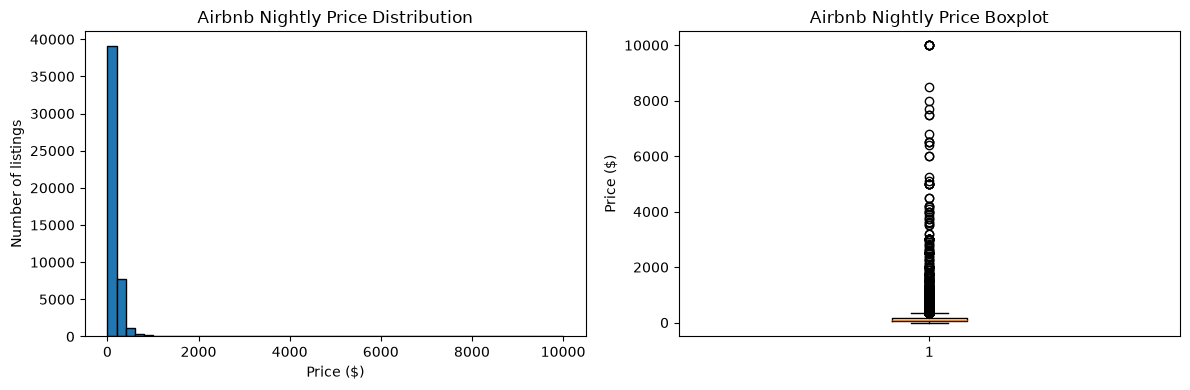

In [10]:
# Visualize the original Airbnb nightly prices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(airbnb_df["price"], bins=50, edgecolor="black")
axes[0].set_title("Airbnb Nightly Price Distribution")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of listings")

# Identify potential outliers with a boxplot
axes[1].boxplot(airbnb_df["price"])
axes[1].set_title("Airbnb Nightly Price Boxplot")
axes[1].set_ylabel("Price ($)")

plt.tight_layout()
plt.show()

### Statistical Measures of Airbnb Prices

We calculate measures of central tendency (mean and median) and dispersion (standard deviation and percentiles).

Comparing these values helps us understand how extreme prices affect the dataset and provides a basis for identifying outliers.

In [11]:
# Calculate measures of central tendency and dispersion
prices = airbnb_df["price"]

mean_price = prices.mean()
median_price = prices.median()
std_price = prices.std()

# Calculate selected price percentiles
percentiles = prices.quantile([0.01, 0.05, 0.25, 0.75, 0.95, 0.99])

print(f"Mean price: ${mean_price:.2f}")
print(f"Median price: ${median_price:.2f}")
print(f"Standard deviation: ${std_price:.2f}")

print("\nPrice percentiles:")
display(percentiles.to_frame(name="Price ($)"))

Mean price: $152.72
Median price: $106.00
Standard deviation: $240.15

Price percentiles:


,Price ($)
0.01,30.0
0.05,40.0
0.25,69.0
0.75,175.0
0.95,355.0
0.99,799.0


### Removing Invalid Prices

Some Airbnb listings have a nightly price of $0. Since our analysis focuses on paid accommodation, we remove listings with prices less than or equal to zero.

We keep the original dataset unchanged and create a separate dataset for further outlier analysis.

In [12]:
# Count listings with invalid nightly prices
invalid_prices = (airbnb_df["price"] <= 0).sum()

# Keep only listings with positive prices
airbnb_valid = airbnb_df[airbnb_df["price"] > 0].copy()

print("Original listings:", len(airbnb_df))
print("Invalid price listings:", invalid_prices)
print("Valid listings:", len(airbnb_valid))

Original listings: 48895
Invalid price listings: 11
Valid listings: 48884


### Outlier Detection Using the Interquartile Range (IQR)

The IQR method identifies outliers using the first quartile (Q1) and third quartile (Q3).

IQR = Q3 - Q1

Values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR are considered potential outliers.

This method is useful for skewed data because it is less sensitive to extreme values than methods based on the mean and standard deviation.

In [13]:
# Calculate quartiles and the interquartile range
Q1 = airbnb_valid["price"].quantile(0.25)
Q3 = airbnb_valid["price"].quantile(0.75)
IQR = Q3 - Q1

# Calculate the lower and upper outlier thresholds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify listings outside the IQR thresholds
iqr_outliers = airbnb_valid[
    (airbnb_valid["price"] < lower_bound) |
    (airbnb_valid["price"] > upper_bound)
]

print(f"Q1: ${Q1:.2f}")
print(f"Q3: ${Q3:.2f}")
print(f"IQR: ${IQR:.2f}")
print(f"Lower bound: ${lower_bound:.2f}")
print(f"Upper bound: ${upper_bound:.2f}")
print("Number of IQR outliers:", len(iqr_outliers))

Q1: $69.00
Q3: $175.00
IQR: $106.00
Lower bound: $-90.00
Upper bound: $334.00
Number of IQR outliers: 2972


### Outlier Detection Using Mean and Standard Deviation

This method identifies prices that fall unusually far from the mean.

We define potential outliers as prices more than three standard deviations above or below the mean.

Unlike the IQR method, this approach is sensitive to extreme values because those values influence both the mean and standard deviation.

In [14]:
# Calculate the mean and standard deviation of valid prices
mean_valid = airbnb_valid["price"].mean()
std_valid = airbnb_valid["price"].std()

# Define outlier thresholds using three standard deviations
std_lower = mean_valid - 3 * std_valid
std_upper = mean_valid + 3 * std_valid

# Identify prices outside the thresholds
std_outliers = airbnb_valid[
    (airbnb_valid["price"] < std_lower) |
    (airbnb_valid["price"] > std_upper)
]

print(f"Mean: ${mean_valid:.2f}")
print(f"Standard deviation: ${std_valid:.2f}")
print(f"Lower bound: ${std_lower:.2f}")
print(f"Upper bound: ${std_upper:.2f}")
print("Number of standard deviation outliers:", len(std_outliers))

Mean: $152.76
Standard deviation: $240.17
Lower bound: $-567.76
Upper bound: $873.27
Number of standard deviation outliers: 388


### Outlier Detection Using Percentiles

The percentile method identifies prices at the extremes of the distribution.

We use the 1st percentile as the lower threshold and the 99th percentile as the upper threshold. Prices outside this range are considered potential outliers.

Unlike the standard deviation method, percentile thresholds are less influenced by extremely expensive listings.

In [15]:
# Calculate the 1st and 99th percentile thresholds
percentile_lower = airbnb_valid["price"].quantile(0.01)
percentile_upper = airbnb_valid["price"].quantile(0.99)

# Identify listings outside the percentile range
percentile_outliers = airbnb_valid[
    (airbnb_valid["price"] < percentile_lower) |
    (airbnb_valid["price"] > percentile_upper)
]

print(f"1st percentile: ${percentile_lower:.2f}")
print(f"99th percentile: ${percentile_upper:.2f}")
print("Number of percentile outliers:", len(percentile_outliers))

1st percentile: $30.00
99th percentile: $799.00
Number of percentile outliers: 867


### Comparing Outlier Detection Methods

We compare the lower and upper price thresholds of the three methods, along with the number and percentage of listings identified as outliers.

This helps us select an appropriate cleaning method for the final dataset.

In [16]:
# Compare thresholds and outlier counts for each method
comparison = pd.DataFrame({
    "Method": ["IQR", "Mean ± 3 Std Dev", "1st–99th Percentile"],
    "Lower Bound ($)": [lower_bound, std_lower, percentile_lower],
    "Upper Bound ($)": [upper_bound, std_upper, percentile_upper],
    "Outliers": [
        len(iqr_outliers),
        len(std_outliers),
        len(percentile_outliers)
    ]
})

# Calculate the percentage of valid listings flagged as outliers
comparison["Outliers (%)"] = (
    comparison["Outliers"] / len(airbnb_valid) * 100
)

display(comparison.round(2))

,Method,Lower Bound ($),Upper Bound ($),Outliers,Outliers (%)
0,IQR,-90.00,334.00,2972,6.08
1,Mean ± 3 Std Dev,-567.76,873.27,388,0.79
2,1st–99th Percentile,30.00,799.00,867,1.77


### Creating the Cleaned Airbnb Dataset

We selected the 1st–99th percentile method because Airbnb prices are right-skewed, and the IQR method may exclude many legitimate higher-priced properties.

The percentile method removes unusually low and high prices while preserving most listings. We also exclude listings with a nightly price of $0.

This approach is appropriate for analyzing typical nightly prices, although some legitimate budget and luxury listings may be excluded.

In [17]:
# Keep listings within the 1st and 99th percentile thresholds
airbnb_clean = airbnb_valid[
    airbnb_valid["price"].between(percentile_lower, percentile_upper)
].copy()

# Compare the original and cleaned datasets
print("Original listings:", len(airbnb_df))
print("Valid listings:", len(airbnb_valid))
print("Cleaned listings:", len(airbnb_clean))
print("Total listings removed:", len(airbnb_df) - len(airbnb_clean))

print("\nCleaned price statistics:")
display(airbnb_clean["price"].describe())

Original listings: 48895
Valid listings: 48884
Cleaned listings: 48017
Total listings removed: 878

Cleaned price statistics:


count    48017.000000
mean       138.502010
std        103.694011
min         30.000000
25%         70.000000
50%        105.000000
75%        175.000000
max        799.000000
Name: price, dtype: float64

### Comparing Original and Cleaned Price Distributions

We compare the original Airbnb prices with the cleaned dataset using histograms and boxplots.

This allows us to visualize the effect of percentile-based outlier removal and determine whether the extreme prices have been reduced.

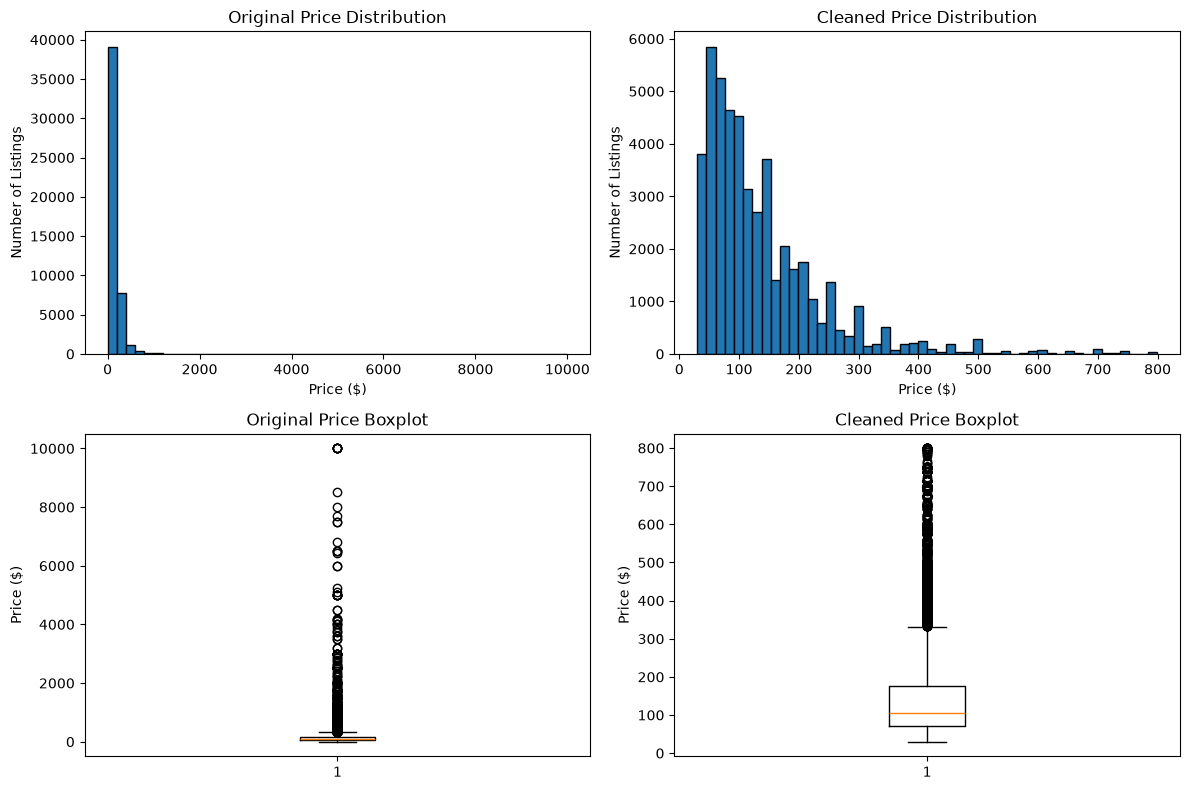

In [18]:
# Compare the original and cleaned price distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(airbnb_df["price"], bins=50, edgecolor="black")
axes[0, 0].set_title("Original Price Distribution")
axes[0, 0].set_xlabel("Price ($)")
axes[0, 0].set_ylabel("Number of Listings")

axes[0, 1].hist(airbnb_clean["price"], bins=50, edgecolor="black")
axes[0, 1].set_title("Cleaned Price Distribution")
axes[0, 1].set_xlabel("Price ($)")
axes[0, 1].set_ylabel("Number of Listings")

axes[1, 0].boxplot(airbnb_df["price"])
axes[1, 0].set_title("Original Price Boxplot")
axes[1, 0].set_ylabel("Price ($)")

axes[1, 1].boxplot(airbnb_clean["price"])
axes[1, 1].set_title("Cleaned Price Boxplot")
axes[1, 1].set_ylabel("Price ($)")

plt.tight_layout()
plt.show()

### Impact of Outlier Removal

We compare the number of listings, mean, median, standard deviation, minimum price, and maximum price before and after cleaning.

This helps evaluate whether percentile-based filtering reduced the influence of extreme prices while preserving most of the dataset.

In [19]:
# Compare summary statistics before and after cleaning
summary = pd.DataFrame({
    "Statistic": [
        "Number of Listings",
        "Mean Price ($)",
        "Median Price ($)",
        "Standard Deviation ($)",
        "Minimum Price ($)",
        "Maximum Price ($)"
    ],
    "Original": [
        len(airbnb_df),
        airbnb_df["price"].mean(),
        airbnb_df["price"].median(),
        airbnb_df["price"].std(),
        airbnb_df["price"].min(),
        airbnb_df["price"].max()
    ],
    "Cleaned": [
        len(airbnb_clean),
        airbnb_clean["price"].mean(),
        airbnb_clean["price"].median(),
        airbnb_clean["price"].std(),
        airbnb_clean["price"].min(),
        airbnb_clean["price"].max()
    ]
})

display(summary.round(2))

# Calculate the percentage of listings retained
retained_percentage = len(airbnb_clean) / len(airbnb_df) * 100

print(f"Listings retained: {retained_percentage:.2f}%")
print(f"Listings removed: {100 - retained_percentage:.2f}%")

,Statistic,Original,Cleaned
0,Number of Listings,48895.00,48017.00
1,Mean Price ($),152.72,138.50
2,Median Price ($),106.00,105.00
3,Standard Deviation ($),240.15,103.69
4,Minimum Price ($),0.00,30.00
5,Maximum Price ($),10000.00,799.00


Listings retained: 98.20%
Listings removed: 1.80%


### Saving the Cleaned Dataset

The final cleaned dataset excludes listings with invalid nightly prices and prices outside the 1st–99th percentile range.

We export the cleaned data to a CSV file so it can be reused for further analysis.

In [20]:
# Save the cleaned Airbnb listings to a CSV file
airbnb_clean.to_csv("AB_NYC_2019_cleaned.csv", index=False)

print("Cleaned dataset saved as AB_NYC_2019_cleaned.csv")
print("Number of cleaned listings:", len(airbnb_clean))

Cleaned dataset saved as AB_NYC_2019_cleaned.csv
Number of cleaned listings: 48017


## Conclusion

### Part A — Spam Classification

Both Gaussian Naive Bayes and Multinomial Naive Bayes were trained to classify emails as spam or ham.

Gaussian Naive Bayes performed better on the test dataset, achieving 96.04% accuracy and a 93.50% F1-score, compared with 94.40% accuracy and a 90.68% F1-score for Multinomial Naive Bayes.

### Part B — Airbnb Outlier Detection

The original Airbnb dataset contained unusually high nightly prices and 11 listings with a price of $0.

We compared three statistical outlier detection methods: IQR, mean ± 3 standard deviations, and the 1st–99th percentile method.

We selected percentile filtering to remove extreme prices while preserving most listings. The resulting dataset is better suited for analyzing typical nightly Airbnb prices, although some legitimate low-cost and luxury listings may have been excluded.